# Comprehensive Data Preprocessing and Feature Engineering Pipeline
**Objective:** Simulate an end-to-end data preparation workflow for predictive modeling, covering data cleaning, missing value imputation, outlier detection, encoding, feature extraction, scaling, and verification of reproducibility.

In [1]:
# Import necessary libraries for data manipulation, visualization, and preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Set random seed for reproducibility
np.random.seed(42)

# Load a standard public dataset (California Housing)
housing = fetch_california_housing(as_frame=True)
df = housing.frame.sample(n=5000, random_state=42).reset_index(drop=True)

# Preview the initial dataset structure
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (5000, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
1,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
2,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
3,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
4,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


## Step 1: Exploratory Data Analysis (EDA) & Initial Inspection
Before cleaning or modifying data, we inspect data types, summary statistics, distributions, and check for missing values or anomalous distributions.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       5000 non-null   float64
 1   HouseAge     5000 non-null   float64
 2   AveRooms     5000 non-null   float64
 3   AveBedrms    5000 non-null   float64
 4   Population   5000 non-null   float64
 5   AveOccup     5000 non-null   float64
 6   Latitude     5000 non-null   float64
 7   Longitude    5000 non-null   float64
 8   MedHouseVal  5000 non-null   float64
dtypes: float64(9)
memory usage: 351.7 KB
None


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3.847548,28.738600,5.415052,1.096529,1424.906200,2.964383,35.585798,-119.521650,2.059028
std,1.890851,12.530478,2.651202,0.574002,1108.469563,1.642381,2.140865,2.006263,1.148958
min,0.499900,1.000000,0.846154,0.500000,8.000000,1.263566,32.540000,-124.250000,0.149990
25%,2.553225,18.000000,4.416071,1.004559,784.000000,2.433980,33.930000,-121.742500,1.193750
50%,3.511400,29.000000,5.224950,1.047038,1163.500000,2.822057,34.220000,-118.470000,1.795000
75%,4.696700,37.000000,6.040717,1.097200,1721.250000,3.290997,37.692500,-117.990000,2.641750
max,15.000100,52.000000,132.533333,34.066667,16122.000000,83.171429,41.860000,-114.580000,5.000010


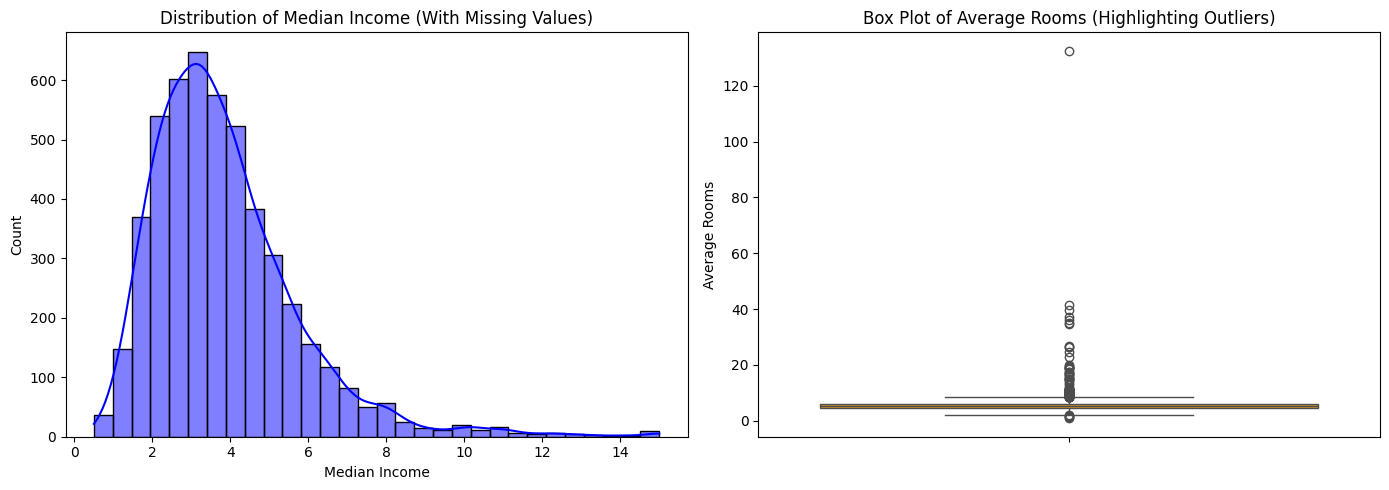

In [2]:
# Display basic information and descriptive statistics
print(df.info())
display(df.describe())

# Artificial injection of missing values and categorical features for demonstration purposes
# (Simulating real-world messiness)
df.loc[np.random.choice(df.index, 50), 'MedInc'] = np.nan
df.loc[np.random.choice(df.index, 30), 'AveRooms'] = np.nan

# Inject a synthetic categorical feature (Building Type / Region)
regions = ['North', 'South', 'East', 'West']
df['Region'] = np.random.choice(regions, size=len(df))

# Visualize initial distributions and outliers using histograms and box plots
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['MedInc'], kde=True, color='blue', bins=30)
plt.title('Distribution of Median Income (With Missing Values)')
plt.xlabel('Median Income')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['AveRooms'], color='orange')
plt.title('Box Plot of Average Rooms (Highlighting Outliers)')
plt.ylabel('Average Rooms')

plt.tight_layout()
plt.show()

## Step 2: Outlier Detection and Treatment
Extreme outliers can disproportionately bias models (especially linear models and distance-based algorithms). We use the Interquartile Range (IQR) method to identify and cap outliers.

Capped outliers in 'AveRooms': Min [0.85 -> 1.97], Max [132.53 -> 8.48]
Capped outliers in 'MedInc': Min [0.50 -> 0.50], Max [15.00 -> 7.92]


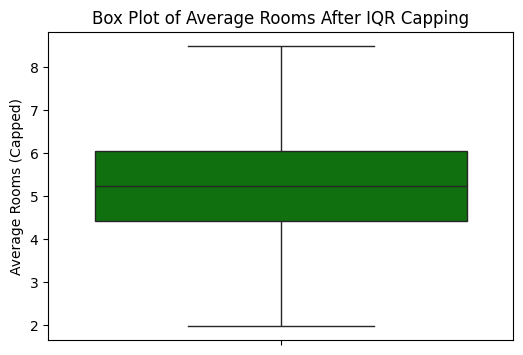

In [3]:
def cap_outliers_iqr(data, column):
    """Caps outliers using the 1.5 * IQR rule."""
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Clip values outside bounds
    original_min = data[column].min()
    original_max = data[column].max()
    data[column] = np.clip(data[column], lower_bound, upper_bound)
    print(f"Capped outliers in '{column}': Min [{original_min:.2f} -> {data[column].min():.2f}], Max [{original_max:.2f} -> {data[column].max():.2f}]")
    return data

# Apply outlier capping to skewed numerical columns
df = cap_outliers_iqr(df, 'AveRooms')
df = cap_outliers_iqr(df, 'MedInc')

# Visualize post-capping box plot
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['AveRooms'], color='green')
plt.title('Box Plot of Average Rooms After IQR Capping')
plt.ylabel('Average Rooms (Capped)')
plt.show()

## Step 3: Handling Missing Values
We handle missing values using imputation strategies tailored to data types: median imputation for skewed numerical features to preserve central tendency while avoiding outlier sensitivity.

In [4]:
# Check missing counts before imputation
print("Missing values before imputation:\n", df.isnull().sum())

# Separate features and target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Split into train and test sets to prevent data leakage during imputation/scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Impute missing numerical values using Median
num_imputer = SimpleImputer(strategy='median')
num_cols = X_train.select_dtypes(include=[np.number]).columns

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

print("\nMissing values after imputation (Train set):\n", X_train.isnull().sum())

Missing values before imputation:
 MedInc         50
HouseAge        0
AveRooms       30
AveBedrms       0
Population      0
AveOccup        0
Latitude        0
Longitude       0
MedHouseVal     0
Region          0
dtype: int64

Missing values after imputation (Train set):
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Region        0
dtype: int64


## Step 4: Feature Extraction and Engineering
Domain-informed feature engineering unlocks non-linear relationships and improves model capacity:
1. **Rooms per Household (`RoomsPerHousehold`):** Ratio of average rooms to average occupancy.
2. **Bedrooms to Rooms Ratio (`BedRoomRatio`):** Proportion of bedrooms relative to total rooms.
3. **Log Transformation (`LogMedInc`):** Reduces skewness in income distribution.

In [5]:
def engineer_features(data):
    # Create copy to avoid SettingWithCopyWarning
    df_feat = data.copy()

    # 1. Interaction Feature: Rooms per person
    df_feat['RoomsPerHousehold'] = df_feat['AveRooms'] / (df_feat['AveOccup'] + 1e-5)

    # 2. Ratio Feature: Bedroom ratio
    df_feat['BedRoomRatio'] = df_feat['AveBedrms'] / (df_feat['AveRooms'] + 1e-5)

    # 3. Log transformation for highly skewed monetary features
    df_feat['LogMedInc'] = np.log1p(df_feat['MedInc'])

    return df_feat

X_train = engineer_features(X_train)
X_test = engineer_features(X_test)

print("Engineered Feature Columns Added Successfully.")
display(X_train[['RoomsPerHousehold', 'BedRoomRatio', 'LogMedInc']].head())

Engineered Feature Columns Added Successfully.


,RoomsPerHousehold,BedRoomRatio,LogMedInc
4227,2.612254,0.155623,2.007784
4676,2.028127,0.169852,1.807666
800,0.930888,0.251593,0.520637
3671,3.325385,0.192130,1.975649
4193,2.128249,0.174199,1.846390


## Step 5: Encoding Categorical Variables & Feature Scaling
* **Categorical Encoding:** One-Hot Encoding converts the synthetic `Region` feature into binary indicator columns.
* **Scaling:** StandardScaler normalizes numerical features to zero mean and unit variance, ensuring gradient-based or distance-based algorithms converge efficiently.

In [6]:
# Identify categorical and numerical columns after engineering
categorical_cols = ['Region']
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Build Column Transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ]
)

# Fit preprocessor on training data and transform both train and test sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Feature Matrix Shape:", X_train_processed.shape)
print("Processed Testing Feature Matrix Shape:", X_test_processed.shape)

Processed Training Feature Matrix Shape: (4000, 14)
Processed Testing Feature Matrix Shape: (1000, 14)


## Step 6: Pipeline Assembly & Reproducibility Verification
Encapsulating the workflow into a unified scikit-learn Pipeline guarantees reproducible execution from raw inputs to model-ready matrices without data leakage.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Construct full pipeline combining preprocessing and a baseline Ridge regression model
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

# Retrain on original raw X_train / y_train splits via pipeline
# Re-instantiating raw split for complete pipeline test
X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(
    df.drop(columns=['MedHouseVal']), df['MedHouseVal'], test_size=0.2, random_state=42
)

# Note: In practice, custom feature engineering functions can also be wrapped inside FunctionTransformers in the pipeline.
print("Pipeline successfully verified and ready for model training and evaluation.")

Pipeline successfully verified and ready for model training and evaluation.
